# 05 — Hopfield recall and noisy switching

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/brains-to-models/blob/main/code/notebooks/05_multistable_dynamics.ipynb)

**Related resources:** [Paper](https://github.com/arvidl/brains-to-models/blob/main/paper/main.pdf) · [Presentation guide](https://github.com/arvidl/brains-to-models/blob/main/talk/resources.md)

## Why this notebook

A system can hold several possible stable states, recover a pattern from a partial cue or switch between alternatives under noise. These phenomena often appear together in discussions of memory and perception, but they are not the same dynamical mechanism. This notebook places three small calculations side by side: binary Hopfield recall, a noisy double well and a soft attention-based retrieval.

Follow the state variable, update rule and diagnostic quantity for each calculation. The 32-unit, two-pattern recall model offers a broader example than the exact 12-unit, one-pattern derivation in notebook 12; either notebook can be read independently.

### Learning goals

1. Distinguish a stored pattern, an initial cue, a trajectory and a fixed point.
2. Explain when Hopfield energy is guaranteed not to increase.
3. Describe how noise can produce switching that deterministic descent would not.
4. Identify what attention retrieval shares with a memory update and what has been omitted.


## Concepts and two reading paths

<details open>
<summary><strong>For biomedical and imaging readers</strong></summary>

**Attractor** is a state, or set of states, approached from a neighborhood under specified dynamics. Its **basin** is the set of starting states that approach it. Pattern completion means that a corrupted cue evolves toward a stored pattern; it does not imply semantic or autobiographical memory.

**Energy** here is a mathematical function of network state. It helps analyze updates but is not measured metabolism. With the required symmetric weights and asynchronous sign updates, it cannot increase. A stable state need not be the one the experimenter intended to retrieve.

**Noisy switching** adds random perturbations to dynamics in a two-well potential. Noise can move a state across a barrier. The resulting switches illustrate a possible mechanism; a sign flip in this simulation is not a participant reporting a percept.

**Attention retrieval** computes a weighted sum of candidate vectors using their similarity to a query. This can sharpen a match without supplying the full recurrent process or biological mechanism of memory.

</details>

<details>
<summary><strong>For computational readers</strong></summary>

For bipolar states $s_i\in\{-1,+1\}$, Hebbian storage uses sums of outer products of patterns, with a zero diagonal. The energy is $E(s)=-\tfrac12s^TWs$. Updating one unit to agree with its local field gives $\Delta E=-(s_i'-s_i)\sum_jW_{ij}s_j\le0$ under the stated assumptions.

Overlap $m_\mu=N^{-1}\xi_\mu^Ts$ measures alignment with pattern $\mu$. Energy and overlap answer different questions: a low-energy state can have the wrong overlap. Multiple stored patterns introduce interactions and potentially additional stable states.

A noisy potential model has the schematic discrete update $x_{t+1}=x_t-\eta U'(x_t)+\sigma\sqrt\eta\,\epsilon_t$. Its trajectory depends on the potential, noise, step size and discretization. A soft retrieval uses weights proportional to $\exp(\beta q^T\xi_\mu)$; increasing $\beta$ concentrates weights but does not establish a general memory-capacity result.

</details>


### Run in Colab or locally

**Colab:** click **Open in Colab**, connect to a standard **CPU** runtime, and run the setup cell followed by the remaining cells (**Runtime → Run all**). Setup obtains the shared code and numerical dependencies.

**Locally:** follow the [environment instructions](https://github.com/arvidl/brains-to-models/blob/main/README.md#run-the-notebooks) and select the project's Python kernel in Cursor or JupyterLab. Setup locates the checkout and sets the working directory to `code/notebooks`, so `%load ../solutions/<filename>.py` works in either environment.

Use **File → Save a copy in Drive** to retain Colab notebook edits, and download generated files before the runtime ends. See the [execution guide](https://github.com/arvidl/brains-to-models/blob/main/code/notebooks/README.md#running-and-saving) for saving outputs and starting a fresh runtime.


In [1]:
# Locate the shared code locally, or download a small checkout in Colab.
import os
from pathlib import Path
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
REPO_URL = os.environ.get("BRAINSMODELS_REPO_URL",
                          "https://github.com/arvidl/brains-to-models.git")
if IN_COLAB:
    root = Path(os.environ.get("BRAINSMODELS_COLAB_ROOT",
                               "/content/brains-to-models"))
    if not (root / "code/src/brainsmodels").is_dir():
        # Sparse checkout keeps the large presentation out of the runtime.
        subprocess.check_call(["git", "clone", "--depth", "1", "--filter=blob:none",
                               "--sparse", "--branch", "main", REPO_URL, str(root)])
        subprocess.check_call(["git", "-C", str(root), "sparse-checkout", "set",
                               "code", "paper/figures"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "numpy>=1.26", "matplotlib>=3.8"])
else:
    here = Path.cwd().resolve()
    root = next((p for p in (here, *here.parents)
                 if (p / "pyproject.toml").is_file()
                 and (p / "code/src/brainsmodels").is_dir()), None)
    if root is None:
        raise RuntimeError("Open this notebook inside a brains-to-models checkout, "
                           "or use its Open in Colab badge.")

src = str(root / "code/src")
if src not in sys.path:
    sys.path.insert(0, src)
# Keep relative exercise paths consistent in Colab, JupyterLab and Cursor.
os.chdir(root / "code/notebooks")
repo = ROOT = root
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
print("Checkout:", root)
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__)
# End of shared setup.

from brainsmodels.repro import DEFAULT_SEED, set_seed
from brainsmodels.dynamics import (
    attention_retrieve,
    corrupt,
    energy,
    hebb_weights,
    hopfield_async,
    make_patterns,
    necker_energy,
    necker_walk,
    overlaps,
    render_paper_figure,
    run_experiment,
    write_figure,
)

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
print("repo root:", root)
print("seed:", SEED)

Checkout: CHECKOUT
Python: 3.12.2 | NumPy: 2.5.2
repo root: CHECKOUT
seed: 7


## Two patterns, one energy

Store $\xi_1,\xi_2\in\{\pm 1\}^{32}$ by the Hebb rule $W=\frac1N\sum_\mu \xi^\mu(\xi^\mu)^\top$ with zero diagonal. The energy $E=-\frac12 s^\top W s$ cannot increase under asynchronous sign updates. A cue is $\xi_1$ with 35% of bits flipped. Recall is whoever’s basin the cue lands in.

**Before running.** The cue is corrupted after storage, so the recall trajectory changes state rather than weights. Read overlap with both stored patterns alongside energy. Predict why an energy decrease alone cannot identify the retrieved pattern, and check the output rather than assuming that the nearest-looking cue must recover the designated memory.


In [2]:
patterns = make_patterns(n=32, seed=SEED)
W = hebb_weights(patterns)
cue = corrupt(patterns[0], frac=0.35, seed=SEED + 3)
recalled, path, energies = hopfield_async(cue, W, n_sweeps=6, seed=SEED)
print("stored energies ", energy(patterns[0], W), energy(patterns[1], W))
print("cue     overlaps", overlaps(cue, patterns), "E", energy(cue, W))
print("recalled overlaps", overlaps(recalled, patterns), "E", energies[-1])
print("energy never rose?", all(energies[i] >= energies[i + 1] - 1e-12 for i in range(len(energies) - 1)))

stored energies  -15.0 -15.0
cue     overlaps [ 0.3125 -0.0625] E -0.625
recalled overlaps [1. 0.] E -15.0
energy never rose? True


## Noisy double-well dynamics

$E(x)=\frac14(x^2-1)^2$ has minima at $x=\pm1$ and a maximum at $0$. The stochastic process $dx=-E'(x)\,dt+\sigma\,dW$ can cross between wells. Compare switching at different noise levels. A relation to bistable perception is an analogy here; no perceptual data are fitted.

**Before running.** Compare the energy at the two wells and the separating saddle before counting switches. A sign change is a convenient numerical event, not a measured percept. To estimate dwell-time behavior you would need a defined observation rule, longer runs and repeated realizations rather than one trace.


In [3]:
walk = necker_walk(seed=SEED)
sign = (walk > 0).astype(int)
print(f"steps {len(walk)}  sign flips {int((sign[1:] != sign[:-1]).sum())}  mean {walk.mean():+.2f}")
print(f"E at wells {float(necker_energy(-1.0)):.3f} {float(necker_energy(1.0)):.3f}  E at saddle {float(necker_energy(0.0)):.3f}")

steps 1600  sign flips 18  mean -0.37
E at wells 0.000 0.000  E at saddle 0.250


## An attention retrieval update

The update $\xi\leftarrow X\,\mathrm{softmax}(\beta X^\top\xi)$ is attention with stored patterns used as both keys and values and one query. Inspect the weights as $\beta$ changes. The relationship concerns this operation, rather than an equivalence between the complete models.


In [4]:
query = 0.55 * patterns[0] + 0.45 * patterns[1]
query = query / np.linalg.norm(query)
for beta in (1.0, 8.0):
    retrieved, w = attention_retrieve(query, patterns, beta)
    print(f"β={beta:.0f}  weights {w[0]:.3f} {w[1]:.3f}  overlap-with-ξ1 {overlaps(np.sign(retrieved), patterns)[0]:+.2f}")

β=1  weights 0.689 0.311  overlap-with-ξ1 +1.00
β=8  weights 0.998 0.002  overlap-with-ξ1 +1.00


## Comparison figure

Inspect recall, nonincreasing energy under asynchronous updates, stochastic switching and continuous retrieval. Identify which dynamics and state variables each panel uses.


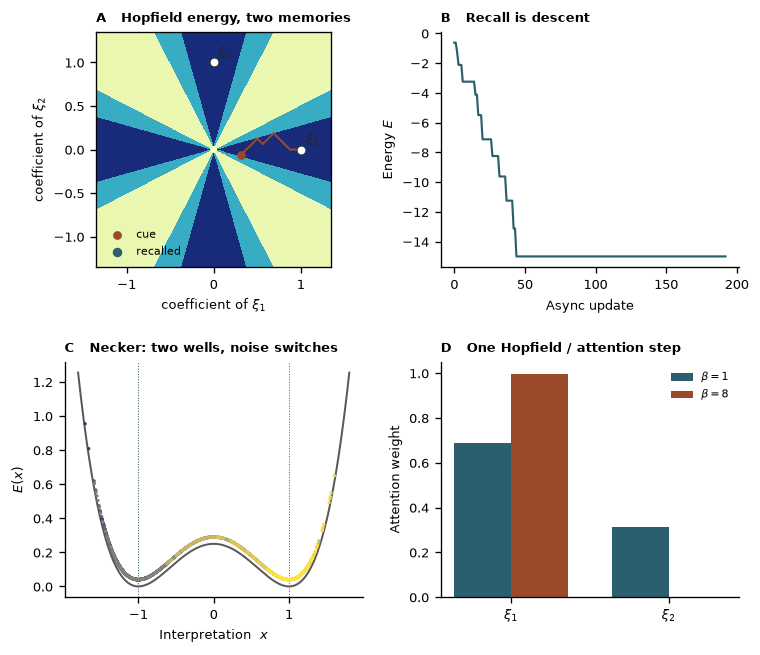

wrote CHECKOUT/paper/figures/multistable_dynamics.pdf
wrote CHECKOUT/paper/figures/multistable_dynamics.png


PosixPath('CHECKOUT/paper/figures/multistable_dynamics.pdf')

In [5]:
result = run_experiment(seed=SEED)
fig = render_paper_figure(result)
plt.show()
write_figure(result, root / "paper" / "figures")

## Compare the mechanisms, not just the pictures

In binary recall, hold the weight matrix fixed and change the corrupted cue. You are probing a basin of the existing dynamics, not retraining the memory. Check both final overlap and energy. Nonincreasing energy is a useful implementation check, but it does not guarantee the desired endpoint. Notebook 12 derives an exact inverse-pattern counterexample.

In the double well, examine the potential's wells and barrier before counting switches. A shallow barrier or stronger noise can change the number of sign changes. A single trace and one seed do not estimate a population dwell-time distribution. To connect the model to perceptual reports, you would need a measurement model, fitted parameters and held-out predictions.

In attention retrieval, inspect both weights and the retrieved vector. A mixed weighted sum need not equal a stored bipolar pattern. Taking its sign introduces an additional decision rule. Changing inverse temperature changes concentration, whereas changing the query changes the evidence being matched. Keep those interventions separate.

### A guided comparison

Make a four-column note for each calculation: state variable, update, diagnostic quantity and failure condition. For the Hopfield model, try simultaneous updates or altered symmetry and reconsider the energy argument. For the double well, remove noise and ask whether switching should persist. For retrieval, use an exactly balanced query and inspect whether a preference comes from symmetry breaking or from the data.

To compare these dynamics with memory or perception, define an observable trajectory and the perturbation predicted to change it. Then ask whether an alternative update rule predicts the same observation. The state equation, observation rule and intervention make the proposed comparison testable.


### Exercises

1. **Corrupt until it fails.** `corrupt(pattern, frac)` flips a fraction of bits, then `hopfield_async` descends. Sweep `frac` from 0 to 0.6 and record whether the final overlap with pattern 0 exceeds 0.8. Where does retrieval break, and why is that not a Necker cube?

<!-- solution-box: 05_1_corrupt_until_it_fails.py -->
<details>
<summary><strong>Show solution</strong> — Corrupt until it fails</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/05_1_corrupt_until_it_fails.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.dynamics import corrupt, hebb_weights, hopfield_async, make_patterns, overlaps
patterns = make_patterns(n=32, seed=SEED)
W = hebb_weights(patterns)
fracs = np.linspace(0.0, 0.6, 13)
ok = []
for frac in fracs:
    cue = corrupt(patterns[0], frac=float(frac), seed=SEED + 3)
    recalled, _, _ = hopfield_async(cue, W, n_sweeps=8, seed=SEED)
    ov = float(overlaps(recalled, patterns)[0])
    ok.append(ov)
    print(f"frac {frac:.2f}  overlap with ξ0 {ov:+.2f}")

fig, ax = plt.subplots(figsize=(5.0, 3.0))
ax.plot(fracs, ok, "o-")
ax.axhline(0.8, color="0.6", ls="--", lw=1)
ax.set_xlabel("flip fraction")
ax.set_ylabel("final overlap with ξ0")
ax.set_title("A Hopfield basin has a radius; past it, recall fails")
plt.tight_layout()
plt.show()
print('Report retrieval success across corruption levels and repeat with several seeds. The result concerns this stored-pattern system; a perceptual interpretation would need separate observations.')
```

</details>
<!-- /solution-box -->


2. **β is the temperature.** `attention_retrieve(query, keys, beta)` is one modern-Hopfield step. Use the notebook’s mixed query ($0.55\,\xi_1+0.45\,\xi_2$) and print the softmax weights at $\beta \in \{0.5, 1, 4, 16\}$. When does the mass collapse onto one key, and why is that still not a transformer layer?

<!-- solution-box: 05_2_beta_is_the_temperature.py -->
<details>
<summary><strong>Show solution</strong> — β is the temperature</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/05_2_beta_is_the_temperature.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.dynamics import attention_retrieve, make_patterns
keys = make_patterns(n=32, seed=SEED)
query = 0.55 * keys[0] + 0.45 * keys[1]
query = query / float(np.linalg.norm(query))
print(f"{'beta':>6}  w(ξ0)   w(ξ1)")
ws = []
for beta in (0.5, 1.0, 4.0, 16.0):
    _, w = attention_retrieve(query, keys, beta)
    ws.append(w)
    print(f"{beta:6.1f}  {w[0]:.3f}   {w[1]:.3f}")

fig, ax = plt.subplots(figsize=(4.6, 3.0))
ax.plot((0.5, 1, 4, 16), [w[0] for w in ws], "o-", label="ξ0")
ax.plot((0.5, 1, 4, 16), [w[1] for w in ws], "s-", label="ξ1")
ax.set_xlabel("β")
ax.set_ylabel("softmax weight")
ax.legend(frameon=False)
ax.set_title("Soft β shares; sharp β retrieves")
plt.tight_layout()
plt.show()
print('Increasing beta sharpens the weights on the stored patterns. This is one attention retrieval operation; a full Transformer also includes learned projections, other sublayers and multiple positions.')
```

</details>
<!-- /solution-box -->


3. **Noise switches the well.** `necker_walk` is Langevin dynamics on $E(x)=\frac{{1}}{{4}}(x^2-1)^2$. Run two walks from $x_0=0$ with `sigma=0.05` and `sigma=0.55` (same seed). Count sign changes of a 40-step moving average. When is the state trapped, and when does it switch? What is still not a cube?

<!-- solution-box: 05_3_noise_switches_the_well.py -->
<details>
<summary><strong>Show solution</strong> — Noise switches the well</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/05_3_noise_switches_the_well.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.dynamics import necker_walk
def n_switches(xs, win=40):
    ma = np.convolve(xs, np.ones(win) / win, mode="valid")
    return int(np.sum(np.diff(np.sign(ma)) != 0))

fig, axes = plt.subplots(2, 1, figsize=(6.0, 4.0), sharex=True)
for ax, sig in zip(axes, (0.05, 0.55)):
    xs = necker_walk(sigma=sig, x0=0.0, seed=SEED)
    ax.plot(xs, lw=0.8)
    ax.axhline(1, color="0.7", ls="--", lw=1)
    ax.axhline(-1, color="0.7", ls="--", lw=1)
    ax.set_ylabel("x")
    ax.set_title(f"σ = {sig}   switches ≈ {n_switches(xs)}", fontsize=9)
axes[-1].set_xlabel("step")
fig.suptitle("The same double well; only the noise scale changed")
plt.tight_layout()
plt.show()
print('Compare the measured switching counts at the two noise levels. This illustrates stochastic transitions in a designed potential; it is not a fit to a perceptual experiment.')
```

</details>
<!-- /solution-box -->


### Questions for reflection

Use these questions to distinguish what the calculation shows from the assumptions and interpretations attached to it. Write an answer before consulting the instructor notes.


1. When is Hopfield energy guaranteed not to increase?

2. Does energy descent guarantee the intended memory?

3. What does the double-well example model?

4. In what sense is modern Hopfield retrieval related to attention?

5. What would turn the analogy into a biological test?


### Further reading

1. **Hopfield, J. J. (1982).** [*Neural networks and physical systems with emergent collective computational abilities*](https://redwood.berkeley.edu/wp-content/uploads/2018/08/hopfield82.pdf). *PNAS* 79(8), 2554–2558.
2. **Ramsauer, H., et al. (2020).** [*Hopfield Networks is All You Need*](https://arxiv.org/abs/2008.02217). arXiv:2008.02217.
3. **Vaswani, A., et al. (2017).** [*Attention Is All You Need*](https://arxiv.org/abs/1706.03762). *NeurIPS* 30. arXiv:1706.03762.
4. **Necker, L. A. (1832).** [*Observations on some remarkable optical phaenomena…*](https://doi.org/10.1080/14786443208647909). *Philosophical Magazine*, series 3, 1(5), 329–337.
5. **Elhage, N., et al. (2021).** [*A Mathematical Framework for Transformer Circuits*](https://transformer-circuits.pub/2021/framework/index.html). *Transformer Circuits Thread*.
6. **Doerig, A., et al. (2023).** [*The neuroconnectionist research programme*](https://konklab.fas.harvard.edu/Papers/Doerig_2023_NRN.pdf). *Nature Reviews Neuroscience* 24, 431–450.
